<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/main/Progetto_NAML_old.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Progetto NAML**

## **TODO**:
- FUNZIONI E MANCANZE:
  - Cross-validation?
  - Nelle implementazioni fom scratch provare ad usare Adam o cose simili?

- COMMENTI E ALTRO (bellezza e organizzazione del notebook):
  - Risistemare l'ordine dei modelli. (idealmente dal più semplice al più complesso)
  - Aggiungere nell'LSTM from scratch la breve spiegazione delle celle LSTM.
  - Aggiungere nell'LSTM from scratch immagine della cella LSTM.
  - Aggiungere immagini per tutte le reti che specificano i layers.
  - Aggiungere formule LATEX per bellezza.

 (NB: tutte le immagini ci possono servire anche per poi metterle nella presentazione)

## **Project Overview**

In recent years, deep learning techniques have demonstrated remarkable success in a wide range of fields, including financial forecasting.

Our project takes inspiration from the work of *Zhang et al. (2019), “Stock Market Prediction Based on Generative Adversarial Network”*, in which the authors propose a novel Generative Adversarial Network (GAN) architecture tailored for stock price forecasting. Their framework combines a **Long Short-Term Memory (LSTM)** network, acting as the **generator**, with a **Multi-Layer Perceptron (MLP)**, acting as the **discriminator**. The **LSTM** is particularly well-suited for handling sequential data, as it can capture temporal dependencies in stock prices, while the **MLP** effectively distinguishes between real and generated data distributions.

Building on this foundation, our work seeks to reproduce and adapt similar ideas, with the aim of exploring the potential of GAN-based architectures for predicting the daily closing price of stocks. In addition to implementing this adversarial approach, we also conducted a comparative analysis with more classical models, including a standalone **LSTM**, a standard Artificial Neural Network (**ANN**), and a Support Vector Machine (**SVM**). This comparison allows us to better evaluate the advantages and limitations of the GAN-based strategy in relation to widely used machine learning techniques.

## **Imports**

In [1]:
!pip uninstall torch
!pip cache purge
!pip install torch --upgrade

Found existing installation: torch 2.8.0+cu126
Uninstalling torch-2.8.0+cu126:
  Would remove:
    /usr/local/bin/torchfrtrace
    /usr/local/bin/torchrun
    /usr/local/lib/python3.12/dist-packages/functorch/*
    /usr/local/lib/python3.12/dist-packages/torch-2.8.0+cu126.dist-info/*
    /usr/local/lib/python3.12/dist-packages/torch/*
    /usr/local/lib/python3.12/dist-packages/torchgen/*
Proceed (Y/n)? Y
  Successfully uninstalled torch-2.8.0+cu126
Files removed: 0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 138.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
from jax import random
from jax.nn import sigmoid

from datetime import datetime

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## **Dataset study**

DOBBIAMO PULIRE IL DATASET: TOGLIERE NULLI (nel metodo per ottenere un sotto-dataset l'ho già implementato) E VEDERE SE ABBIAMO OUTSIDERS (NEL CASO POSSIAMO VEDERE COSA SUCCEDE E SE HANNO IMPATTO).
DOBBIAMO VEDERE ANCHE SE SCALARE/NORMALIZZARE I DATI?

In [4]:
# !pip install tensorflow

In [5]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [6]:
latest_date = pd.to_datetime(df['date']).max()

one_year_before = latest_date - pd.DateOffset(years=1)

date_series = pd.to_datetime(df['date'])
mask = (date_series >= one_year_before) & (date_series <= latest_date) & (df['Name'] == 'AAPL')

filtered_df = df[mask]
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

/tmp/ipython-input-1817002058.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['date'] = pd.to_datetime(filtered_df['date'])


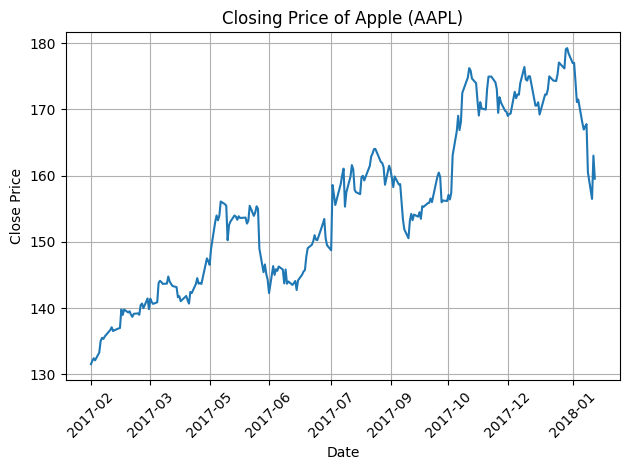

In [7]:
plt.plot(filtered_df['date'], filtered_df['close'])
plt.ylabel('Close Price')
plt.xlabel('Date')
plt.title("Closing Price of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

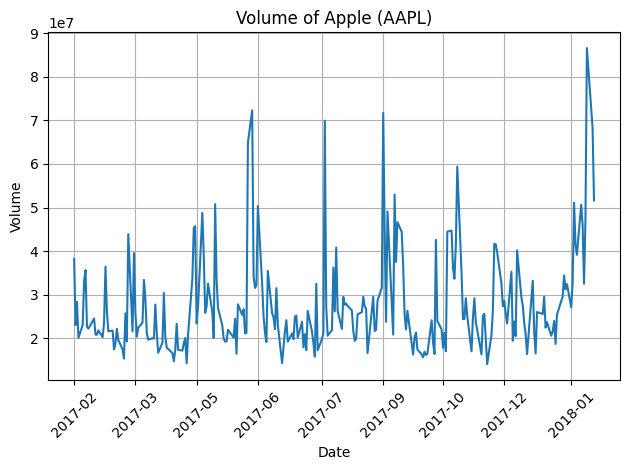

In [8]:
plt.plot(filtered_df['date'], filtered_df['volume'])
plt.ylabel('Volume')
plt.xlabel('Date')
plt.title("Volume of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

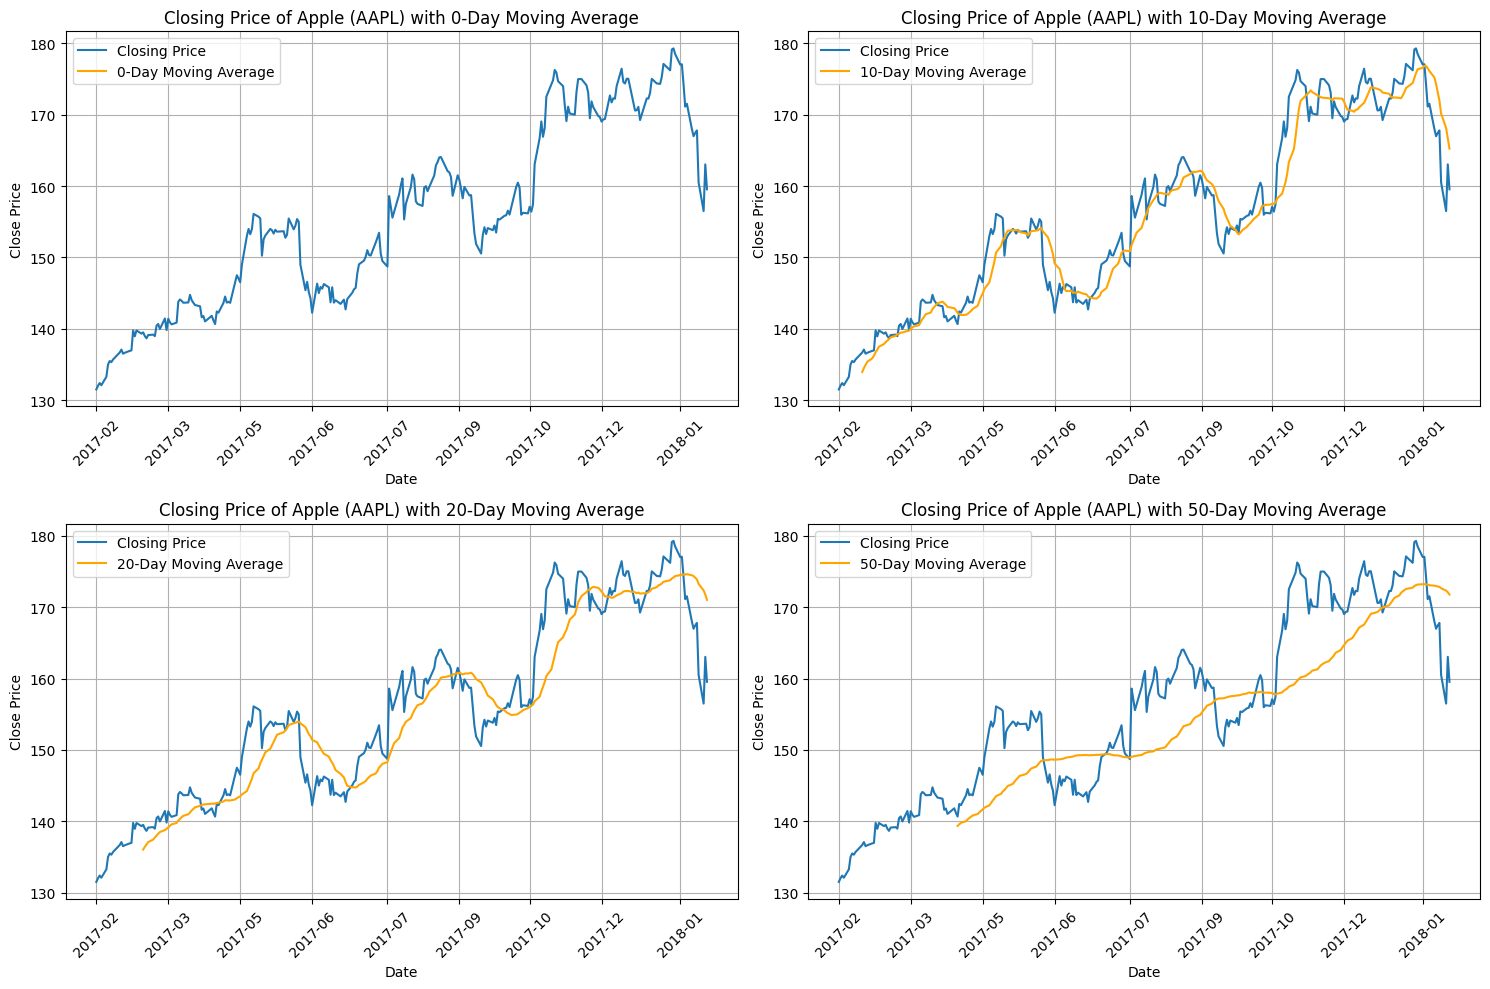

In [9]:
import matplotlib.pyplot as plt

ma_day = [0, 10, 20, 50]  # Diversi periodi per la media mobile
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))  # Creazione di una figura 2x2

# Ciclo per calcolare e tracciare la media mobile per ciascun valore di 'ma'
for i, ma in enumerate(ma_day):
    # Crea una copia del dataset per ogni 'ma'
    df_copy = filtered_df.copy()
    df_copy['ma_close'] = df_copy['close'].rolling(ma).mean()

    # Seleziona l'asse per il grafico
    ax = axes[i // 2, i % 2]  # Seleziona l'asse giusto (2 righe, 2 colonne)

    # Plot del prezzo di chiusura
    ax.plot(df_copy['date'], df_copy['close'], label='Closing Price')

    # Plot della media mobile
    ax.plot(df_copy['date'], df_copy['ma_close'], label=f'{ma}-Day Moving Average', color='orange')

    # Aggiungi etichette, titolo e legenda
    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_title(f"Closing Price of Apple (AAPL) with {ma}-Day Moving Average")
    ax.legend()

    # Mostra solo alcune date sull'asse X
    step = 30
    ax.set_xticks(df_copy['date'][::step])
    ax.set_xticklabels(df_copy['date'].dt.strftime('%Y-%m')[::step], rotation=45)

    # Mostra la griglia
    ax.grid(True)

# Ottimizza la visualizzazione
plt.tight_layout()
plt.show()

## **Network setup**

### **Training dataset setup**

In [10]:
# Facciamo una split del dataset per avere training, validation (vediamo poi se e come usarlo) e test set.
'''
  1. decidere che dati utilizzare
  2. vettore 'input data' usato dal paper: [high_price, low_price, open_price, close_price, volume, turnover_rate, Ma(5)]
'''

"\n  1. decidere che dati utilizzare\n  2. vettore 'input data' usato dal paper: [high_price, low_price, open_price, close_price, volume, turnover_rate, Ma(5)]\n"

In [11]:
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


#### **Step 1) select a single company and complete the dataset**

*We filter our dataset to have data of the company "APPLE" and we compute the MA(5)*

In [12]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [13]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels], df_company[close_data]

In [14]:
df_apple, apple_closings = get_dataframe(df, ['AAPL'])
df_apple.head()

,high,low,open,volume,ma5
1263,67.3771,66.2885,66.3599,88809154,67.32592
1264,67.1656,65.7028,66.9785,97924631,66.90250
1265,66.1042,64.8356,65.8714,108854046,66.33278
1266,65.3842,64.1142,65.3842,118891367,65.78850
1267,64.1671,63.2599,63.7142,111596821,65.18994


In [15]:
df_apple.shape[0]

1255

##### **Analysis of dataset size per individual company**

In [16]:
company_sizes = {}
companies = df['Name'].unique()

for company in companies:
  df_company, company_closings = get_dataframe(df, [company])
  company_sizes[company] = df_company.shape[0]

In [17]:
key_max = max(company_sizes, key=company_sizes.get)
val_max = company_sizes[key_max]

key_min = min(company_sizes, key=company_sizes.get)
val_min = company_sizes[key_min]

# Output
print(f"MAX → {key_max}: {val_max}")
print(f"MIN → {key_min}: {val_min}")

MAX → AAL: 1255
MIN → APTV: 40


#### **Splitting the dataset**

MI MANCA DA SEPARARE LE LABELS (RIFERIMENTO AL CLOSING PRICE)

## **GAN**

In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [61]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1129, 5)
(1129, 1)
(126, 5)
(126, 1)


### **Discriminator and Generator**

In [62]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.

      Cose da notare / considerare:
        - Dato che stiamo usando un MLP, vuoi un input a forma di vettore, però nel paper viene usato un input che prevede più samples.
          In particolare costruisce una matrice X formata da (t + 1) time steps (presi dai dati reali).
          I primi t valori saranno presi dal dattaset, mentre l'ultimo verrà o generato dal generatore, oppure preso anch'esso dal dataset reale.

        - A seguito di quanto detto nel punto prima, sarà anche da considerare l'ampiezza dell'intervallo di time steps come hyperparameter.

        - Andrà anche considerato che nel nostrto dataset, non abbiamo un dato per ogni giorno specifico.
          Potrebbe essere sensato kl non considare questo aspetto poichè alla fine non poniamo le date come un input utile.
          Se volessimo però avere una predizione che considera la data, cioè vogliamo considerare anche che c'è una dipendenza dagli effetivi giorni che separano un sample al tempo t e al tempo t+1,
            dovremmo intervenire in qualche modo.
          (da notare che attualmente le moving average non tengono conto di questo)

        - Come gestiamo la differenza dimensionale tra gli input?
          Soluzione 1: Usiamo un reshape che rende unidimensionale la matrice concatenando un sample dietro l'altro
  '''

  '''
    seq_len: la sequence size
    t_features: è il numero di features per ogni sample.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability. <---
    # After the first, second, and third hidden layers, you use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # You use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model you’ve defined without any other processing.

  def forward(self, x):
    # x shape attesa: (batch_size, t_input, n_features)
    # Flatten temporale e feature dimensioni → (batch_size, t_input * n_features)
    # print(f"From discriminator (input_shape): {x.shape}")
    X_flat = x.view(x.size(0), -1)
    # print(f"From discriminator (X_flat_shape): {X_flat.shape}")
    return self.model(X_flat)

In [63]:
class GeneratorLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, seq_len):
      '''
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h (dimensione hidden layer della lstm -> non dipende dai nostri dati, ma è un hyperparameter)
        * num_layers – Number of recurrent layers. (a quanto pare quanti strati di LSTM usiamo)
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(GeneratorLSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, :, :]
      out = self.fc(out)

      return out

### **Training**

In [64]:
from torch.utils.data import Dataset

class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [65]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

datasetGAN = MyGANDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(datasetGAN, batch_size=32, shuffle=False)

In [66]:
# per debug, lascio questa stampa dei batch creati automaticamente dal dataloader
for i, (x_batch, y_batch) in enumerate(loader):
    print(f"Batch {i+1}: {x_batch.size}")
    print("x_batch shape:", x_batch.shape)
    print("y_batch shape:", y_batch.shape)
    print("-" * 30)
    if i == 0:
        break

Batch 1: <built-in method size of Tensor object at 0x7d1a53b26260>
x_batch shape: torch.Size([32, 10, 5])
y_batch shape: torch.Size([32, 10, 1])
------------------------------


In [71]:
def get_fake_labels(real_labels, output_LSTM):
  # real_labels (batch_size, seq_len, 1)
  # output_LSTM (batch_size, seq_len, 1)

  last_step_output = output_LSTM[:, -1, :]

  y_fake = real_labels.clone()
  y_fake[:, -1, :] = last_step_output

  return y_fake

In [73]:
generator = GeneratorLSTM(input_size=5, hidden_size=32, num_layers=1, seq_len=10)
x_batch, y_batch = next(iter(loader))
outputs = generator(x_batch)
print(outputs.shape)

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


torch.Size([32, 10, 1])


In [74]:
y_batch[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [-1.5127]], device='cuda:0')

In [75]:
get_fake_labels(y_batch, outputs)[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [-0.2006]], device='cuda:0', grad_fn=<SelectBackward0>)

In [76]:
import torch.nn.functional as F

def discriminator_loss(D_real, D_fake):
    # Small epsilon to prevent log(0)
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss = F.mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = torch.mean(torch.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss + lambda2 * adv_loss

In [77]:
def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=False)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      X_real = samples.to(device)
      y_real = labels.to(device)

      # print(f"y_real shape: {y_real.shape}")

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # print(f"y-fake shape: {y_fake.shape}")

      # Training the discriminator
      discriminator.zero_grad() # In PyTorch, it’s necessary to clear the gradients at each training step to avoid accumulating them. You do this using .zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      # You calculate the gradients to update the weights with loss_discriminator.backward()
      loss_discriminator.backward()
      # You update the discriminator weights by calling optimizer_discriminator.step()
      discriminator_optimizer.step()

      # Training the generator
      generator.zero_grad()

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      output_discriminator_generated = discriminator(y_fake)

      # You calculate the loss function using the output of the classification system stored in output_discriminator_generated and the labels in real_samples_labels, which are all equal to 1.
      loss_generator = generator_loss(
        output_discriminator_generated, output_LSTM, y_real
      )

      G_losses.append(loss_generator.item())

      loss_generator.backward()
      generator_optimizer.step()

    # Show loss
    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [78]:
# hyperparameters
input_size = 5
hidden_size = 32
num_layers = 1
num_epochs = 500
lr = 0.001
seq_len = 40

generator = GeneratorLSTM(input_size, hidden_size, num_layers, seq_len)
discriminator = Discriminator(seq_len)
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=lr)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr)

In [79]:
discriminator_losses, generator_losses = train_GAN(
    generator,
    discriminator,
    lr,
    lr,
    num_epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len)

RuntimeError: Input and parameter tensors are not at the same device, found input tensor at cuda:0 and parameter tensor at cpu

In [ ]:
def test_GAN(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(last_step_output.cpu().numpy())
      actuals.extend(last_step_label.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, nn.MSELoss())

In [ ]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_GAN, actuals_GAN)

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("discriminator loss trend")


plt.grid(True)


plt.show()

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("generator loss trend")


plt.grid(True)


plt.show()

## **LSTM (with Pytorch)**

Here we implement the **LSTM** using the **PyTorch** library, which provides **high-level modules** for defining the network and handling training efficiently.

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
This class will be used to create a **data loader** that provides the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**. This structure is necessary because, in this implementation, we use PyTorch libraries that require data to have these shapes.

In [ ]:
class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len]

      return x, y

### **Pytorch LSTM implementation**

This is our PyTorch implementation of an LSTM model for time series prediction. The architecture consists of the following components:

 - **LSTM Layer**: Processes the input sequences and captures temporal dependencies
  - *input_size* specifies the number of features in each time step.
  - *hidden_size* is the number of features in the hidden state, controlling the model’s capacity to learn patterns.
  - *num_layers* allows stacking multiple LSTM layers to capture more complex sequential patterns.
  - *batch_first*=True ensures that the input tensor has shape (batch_size, seq_len, input_size), which aligns with our dataset loader.
  - dropout=0.3 applies dropout between LSTM layers (if stacked) to reduce overfitting.

 - **Fully Connected Layer**: Maps the hidden state of the last time step to the output prediction. Since we are predicting a single value (the **closing price**), the output dimension is 1.

In [ ]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
      '''
        From pyorch documentation:
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h
        * num_layers – Number of recurrent layers.
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(LSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, -1, :]
      out = self.fc(out)

      return out

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [ ]:
# hyperparameters
input_size = 5
hidden_size = 32
num_layers = 1
num_epochs = 500
lr = 0.001
seq_len = 40

model = LSTM(input_size, hidden_size, num_layers)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using PyTorch’s compact framework.

In [ ]:
def train_LSTM(model, learning_rate, epochs, loss_function, optimizer, seq_len):
  dataset = MyDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)
  # Train the model
  n_total_steps = len(loader)
  losses = []

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      samples = samples.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)

      losses.append(loss.item())
      # Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

  return losses

In [ ]:
losses = train_LSTM(model, lr, num_epochs, loss_function, optimizer, seq_len)

Epoch [1/500], Step [35/35], Loss: 1.9786
Epoch [51/500], Step [35/35], Loss: 0.0039
Epoch [101/500], Step [35/35], Loss: 0.0010
Epoch [151/500], Step [35/35], Loss: 0.0008
Epoch [201/500], Step [35/35], Loss: 0.0000
Epoch [251/500], Step [35/35], Loss: 0.0001
Epoch [301/500], Step [35/35], Loss: 0.0002
Epoch [351/500], Step [35/35], Loss: 0.0003
Epoch [401/500], Step [35/35], Loss: 0.0002
Epoch [451/500], Step [35/35], Loss: 0.0008


### **Learning of our LSTM**

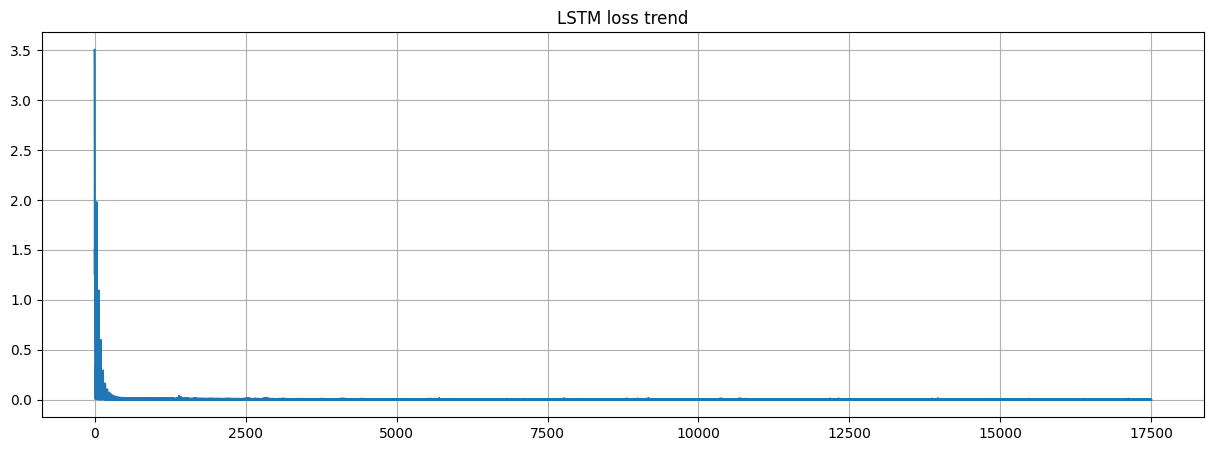

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")

plt.grid(True)

plt.show()

### **Testing**

In [ ]:
def test_LSTM(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())
      actuals.extend(y_batch.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_LSTM, actuals_LSTM = test_LSTM(model, seq_len, loss_function)

Test Loss: 0.0067


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our LSTM model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [ ]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

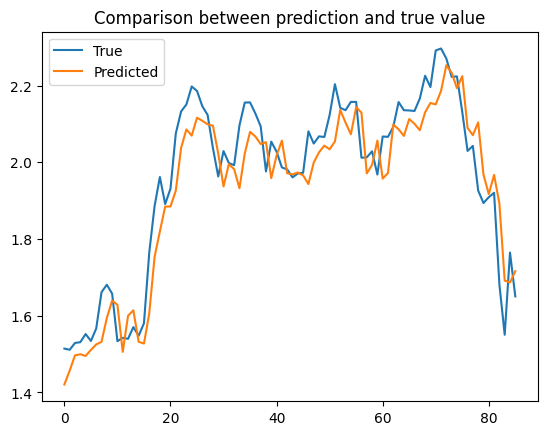

In [ ]:
plot_predictions(preds_LSTM, actuals_LSTM)

##**LSTM (from scratch)**

In the following section, we will implement an **LSTM** using standard **JAX** libraries together with **JIT** compilation. JAX allows us to define the model and training loop in a NumPy-like syntax, while jit compiles these operations into highly **optimized code**. This compilation enables efficient parallel execution and full utilization of GPU acceleration.

During training, the forward and backward passes are transformed into **optimized computational graphs**, allowing gradient computations and parameter updates to be executed much faster than with a purely Python implementation. Thanks to these optimizations, the training process becomes feasible in terms of execution time, even for models working on large sequential datasets.

In [151]:
print(jax.devices())

[CudaDevice(id=0)]


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [152]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
In this case, the dataset will be used to train an LSTM implemented from scratch. We still rely on the dataset and data loader to keep **consistency** between the two implementations, providing the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**.

In [153]:
class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len]

      return x, y

In [154]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [155]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

In [156]:
chosen_loss = mse_loss

### **Implementation**

In [157]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq[-1]  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])

class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found **empirically** to give the best results.

In [158]:
# hyperparameters
input_size = 5
hidden_size = 48
num_epochs = 500
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using our LSTM implementation from scratch, relying on **JAX** and **JIT** to efficiently handle **gradient computations** and **parameter updates**.

In [159]:
def train_step(params, X_batch, Y_batch, lr, model, loss_function):
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return loss_function(Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames=['model', 'loss_function'])

def train_LSTM_scratch(model, X_train, y_train, seq_len, loss_function, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, output_size)
    """

    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Conversion in jax arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Update of the model parameters
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model, loss_function)

            # Batch loss
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = loss_function(Y_pred, Y_batch)
            losses.append(batch_loss)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)


        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [160]:
losses = train_LSTM_scratch(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

Epoch [50/500], Loss: 0.005206 [2025-08-24 17:30:23.461161]
Epoch [100/500], Loss: 0.004506 [2025-08-24 17:30:28.788155]
Epoch [150/500], Loss: 0.003981 [2025-08-24 17:30:35.443279]
Epoch [200/500], Loss: 0.003677 [2025-08-24 17:30:41.300010]
Epoch [250/500], Loss: 0.003477 [2025-08-24 17:30:47.895105]
Epoch [300/500], Loss: 0.003331 [2025-08-24 17:30:53.172053]
Epoch [350/500], Loss: 0.003306 [2025-08-24 17:30:59.764494]
Epoch [400/500], Loss: 0.003271 [2025-08-24 17:31:05.138613]
Epoch [450/500], Loss: 0.003174 [2025-08-24 17:31:11.759831]
Epoch [500/500], Loss: 0.003247 [2025-08-24 17:31:17.275935]


### **Learning of our LSTM**

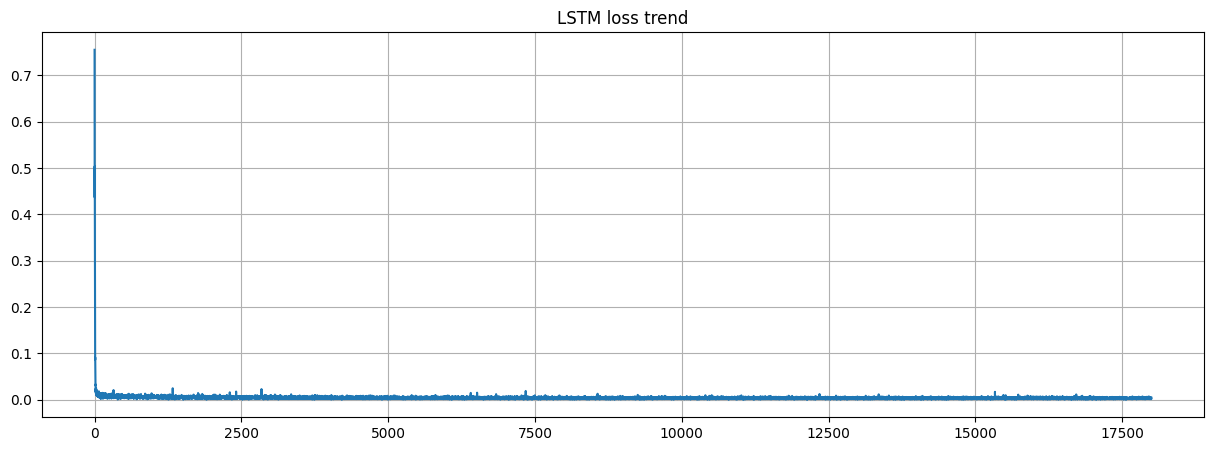

In [161]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")

plt.grid(True)

plt.show()

### **Testing**

In [162]:
def test_LSTM_scratch(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = loss_function(Y_pred, Y_batch)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [163]:
preds_LSTM_scratch, actuals_LSTM_scratch = test_LSTM_scratch(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)

Test Loss: 0.0063


### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **LSTM** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process. Moreover, the results are **comparable to those obtained with the PyTorch implementation**, which suggests that we have achieved a solid level of precision.

In [164]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

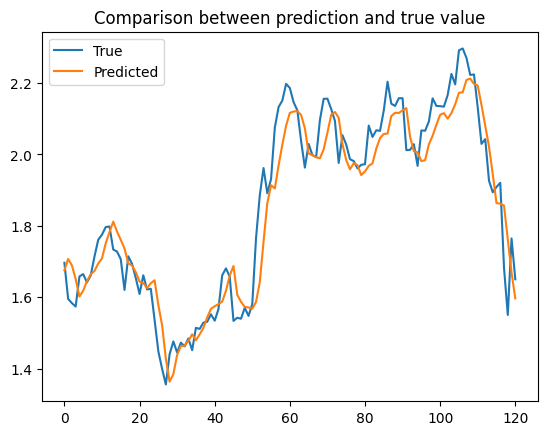

In [165]:
plot_predictions(preds_LSTM_scratch, actuals_LSTM_scratch)

##**GAN Implementation**

### **Discriminator and Generator**

In [200]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.

      Cose da notare / considerare:
        - Dato che stiamo usando un MLP, vuoi un input a forma di vettore, però nel paper viene usato un input che prevede più samples.
          In particolare costruisce una matrice X formata da (t + 1) time steps (presi dai dati reali).
          I primi t valori saranno presi dal dattaset, mentre l'ultimo verrà o generato dal generatore, oppure preso anch'esso dal dataset reale.

        - A seguito di quanto detto nel punto prima, sarà anche da considerare l'ampiezza dell'intervallo di time steps come hyperparameter.

        - Andrà anche considerato che nel nostrto dataset, non abbiamo un dato per ogni giorno specifico.
          Potrebbe essere sensato kl non considare questo aspetto poichè alla fine non poniamo le date come un input utile.
          Se volessimo però avere una predizione che considera la data, cioè vogliamo considerare anche che c'è una dipendenza dagli effetivi giorni che separano un sample al tempo t e al tempo t+1,
            dovremmo intervenire in qualche modo.
          (da notare che attualmente le moving average non tengono conto di questo)

        - Come gestiamo la differenza dimensionale tra gli input?
          Soluzione 1: Usiamo un reshape che rende unidimensionale la matrice concatenando un sample dietro l'altro
  '''

  '''
    seq_len: la sequence size
    t_features: è il numero di features per ogni sample.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability. <---
    # After the first, second, and third hidden layers, you use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # You use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model you’ve defined without any other processing.

  def forward(self, x):
    # x shape attesa: (batch_size, t_input, n_features)
    # Flatten temporale e feature dimensioni → (batch_size, t_input * n_features)
    # print(f"From discriminator (input_shape): {x.shape}")
    X_flat = x.view(x.size(0), -1)
    # print(f"From discriminator (X_flat_shape): {X_flat.shape}")
    return self.model(X_flat)

In [201]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq  # (seq_len,output_size)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])



In [202]:
class GeneratorLSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)

### **Training**

In [203]:
from torch.utils.data import Dataset

class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

In [204]:
def get_fake_labels(real_labels, output_LSTM):
    # real_labels (batch_size, seq_len, 1)
    # output_LSTM (batch_size, seq_len, 1)

    last_step_output = output_LSTM[:, -1, :]  # (batch_size, 1)

    y_fake = jnp.array(real_labels, dtype=jnp.float32)
    y_fake = y_fake.at[:, -1, :].set(last_step_output)
    return torch.tensor(np.array(y_fake), dtype=torch.float32)

In [205]:
def discriminator_loss(D_real, D_fake):
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss_val = mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = jnp.mean(jnp.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss_val + lambda2 * adv_loss

In [206]:
def train_step_generator(params, X_batch, Y_batch, lr, model, generator_loss, D_out):
    """
    Esegue un passo di training su un batch jittato.
    """
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return generator_loss(D_out, Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_generator_jit = jax.jit(train_step_generator, static_argnames=['model', 'generator_loss'])



def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=False)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  for epoch in range(epochs):
    for i, (x_real, y_real) in enumerate(loader):

      X_batch = jnp.array(x_real, dtype=jnp.float32)
      Y_batch = jnp.array(y_real, dtype=jnp.float32)
      output_LSTM = generator.forward_batch(generator.params, X_batch)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # Training the discriminator

      discriminator.zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      loss_discriminator.backward()
      discriminator_optimizer.step()

      # Training the generator

      # Batch loss
      output_LSTM = generator.forward_batch(generator.params, X_batch)

      Y_fake = get_fake_labels(Y_batch, output_LSTM)

      output_discriminator_generated = discriminator(Y_fake)

      D_output_array = jnp.array(output_discriminator_generated.detach().cpu().numpy(), dtype=jnp.float32)
      loss_generator = generator_loss(
        D_output_array, output_LSTM, Y_batch
      )

      G_losses.append(loss_generator.item())

      generator.params = train_step_generator_jit(generator.params, X_batch, Y_batch, learning_rate_generator, generator, generator_loss, D_output_array)

    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [207]:
# hyperparameters
input_size = 5
hidden_size = 48
num_layers = 1
num_epochs = 500
lr_D = 0.005
lr_G =0.055
seq_len = 5

generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)
discriminator = Discriminator(seq_len)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr_D)

In [208]:
discriminator_losses, generator_losses = train_GAN(
    generator,
    discriminator,
    lr_D,
    lr_G,
    num_epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len)

Epoch: 0 Loss D.: 1.3928205966949463
Epoch: 0 Loss G.: 0.02890920639038086
Epoch: 50 Loss D.: 1.402583360671997
Epoch: 50 Loss G.: -0.15276050567626953
Epoch: 100 Loss D.: 1.4035804271697998
Epoch: 100 Loss G.: -0.15661273896694183
Epoch: 150 Loss D.: 1.3904134035110474
Epoch: 150 Loss G.: -0.15173129737377167
Epoch: 200 Loss D.: 1.2322947978973389
Epoch: 200 Loss G.: -0.18533146381378174
Epoch: 250 Loss D.: 1.3768826723098755
Epoch: 250 Loss G.: -0.18680274486541748
Epoch: 300 Loss D.: 1.5014680624008179
Epoch: 300 Loss G.: -0.24268513917922974
Epoch: 350 Loss D.: 1.3645613193511963
Epoch: 350 Loss G.: -0.19670987129211426
Epoch: 400 Loss D.: 1.3914449214935303
Epoch: 400 Loss G.: -0.20663343369960785
Epoch: 450 Loss D.: 1.363508939743042
Epoch: 450 Loss G.: -0.20677466690540314


In [209]:
def test_GAN(model, seq_len, loss_function):
  #model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      X_batch = jnp.array(x_batch, dtype=jnp.float32)
      Y_batch = jnp.array(y_batch, dtype=jnp.float32)
      outputs = model.forward_batch(model.params, X_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = Y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss * X_batch.shape[0]

      preds.extend(last_step_output)
      actuals.extend(last_step_label)

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [210]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, chosen_loss)

Test Loss: 0.0020


In [211]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

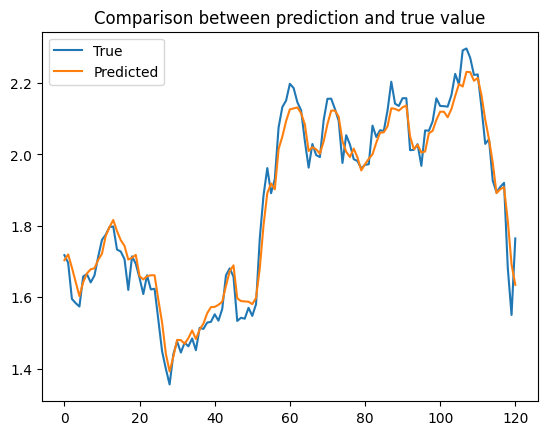

In [212]:
plot_predictions(preds_GAN, actuals_GAN)

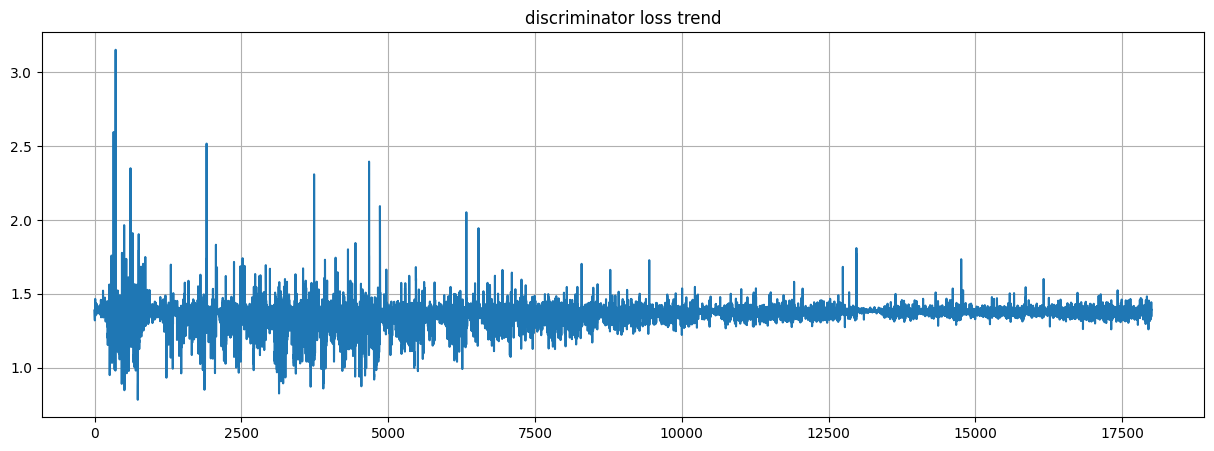

In [213]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("discriminator loss trend")


plt.grid(True)


plt.show()

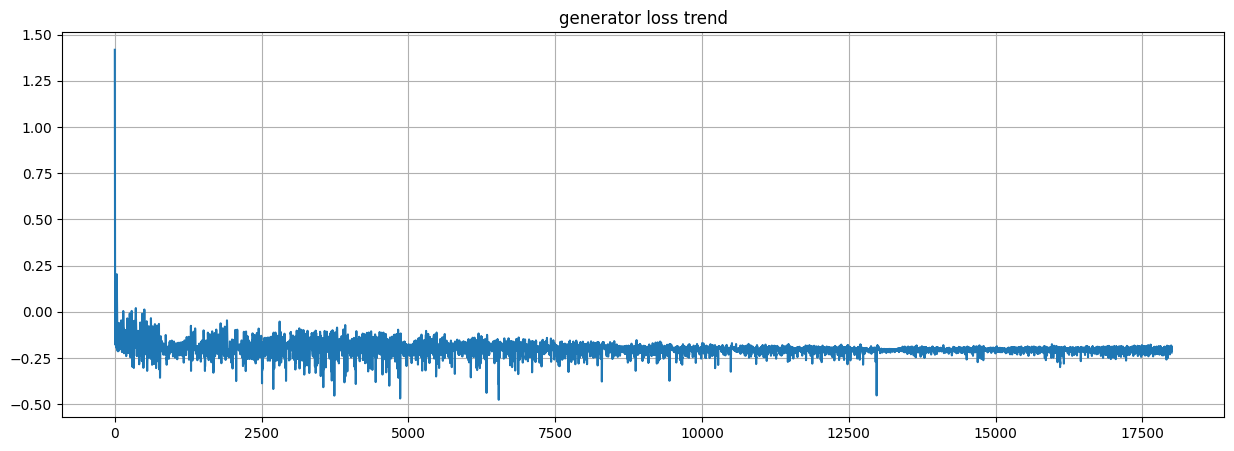

In [214]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")
# plt.ylabel('Close Price')
# plt.xlabel('Date')

plt.title("generator loss trend")


plt.grid(True)


plt.show()

##**SVM**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ["APPL"])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

ValueError: Found array with 0 sample(s) (shape=(0, 5)) while a minimum of 1 is required by StandardScaler.

In [ ]:
X_train

array([[-1.3940899 , -1.3845874 , -1.4043342 ,  1.0569389 , -1.3703785 ],
       [-1.4009941 , -1.4039029 , -1.3840498 ,  1.3319478 , -1.3842849 ],
       [-1.4356424 , -1.4325018 , -1.4203525 ,  1.6616822 , -1.4029961 ],
       ...,
       [ 1.5446123 ,  1.5637349 ,  1.5373266 , -1.0021052 ,  1.5184145 ],
       [ 1.5942311 ,  1.596057  ,  1.5697894 , -0.96256906,  1.5846257 ],
       [ 1.689225  ,  1.6488193 ,  1.6202871 , -0.5300726 ,  1.5944129 ]],
      dtype=float32)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1129, 5)
(1129, 1)
(126, 5)
(126, 1)


In [ ]:
from torch.utils.data import Dataset

class MySVMDataset(Dataset):
    def __init__(self, X_data, y_data):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)

    def __len__(self):
      return len(self.y_data)

    def __getitem__(self, idx):
      x = self.X_data[idx]
      y = self.y_data[idx]

      return x, y

In [ ]:
from torch.utils.data import DataLoader

dataset = MySVMDataset(X_train, y_train)
loader_ANN = DataLoader(dataset, batch_size=32, shuffle=True)

In [ ]:
class SVM(nn.Module):
  def __init__(self, input_dim, bias=True):
    super(SVM, self).__init__()
    self.linear = nn.Linear(input_dim, 1, bias=bias)

  def forward(self, x):
    if x.dim() == 3:
            B, T, F = x.shape
            x = x.view(B, T * F)
    return self.linear(x)

In [ ]:
def epsilon_insensitive_loss(y_pred, y_true, epsilon=0.01, reduction='mean'):
    """
    loss = mean( max(0, |y - y_hat| - epsilon) )
    """
    # ensure 1D
    y_pred = y_pred.view(-1)
    y_true = y_true.view(-1)
    diff = torch.abs(y_true - y_pred) - epsilon
    loss = torch.clamp(diff, min=0.0)
    if reduction == 'mean':
        return loss.mean()
    elif reduction == 'sum':
        return loss.sum()
    else:
        return loss  # no reduction

In [ ]:
# hyperparameters
input_size = 5
num_epochs = 100
lr = 0.001

model = SVM(input_size)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [ ]:
def train_SVM(model, epochs, loss_function, optimizer, epsilon=0.01):
  dataset = MySVMDataset(X_train, y_train)
  loader_SVM = DataLoader(dataset, batch_size=32, shuffle=True)

  n_total_steps = len(loader)

  model.to(device)
  model.train()

  for epoch in range(epochs):
    epoch_loss = 0
    for i, (samples, labels) in enumerate(loader_SVM):
      samples = samples.to(device)
      labels = labels.to(device)



      # Forward pass
      outputs = model(samples)
      loss = epsilon_insensitive_loss(outputs, labels, epsilon=epsilon, reduction='mean')
      epoch_loss += loss.item()
      # Backward and optimize
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

In [ ]:
train_SVM(model, num_epochs, loss_function, optimizer)

Epoch [1/100], Step [36/35], Loss: 1.2276
Epoch [51/100], Step [36/35], Loss: 0.0094


In [ ]:
def test_SVM(model, loss_function,  epsilon=0.01):
  dataset = MySVMDataset(X_test, y_test)
  loader_SVM = DataLoader(dataset, batch_size=32, shuffle=False)

  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader_SVM):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = epsilon_insensitive_loss(outputs, y_batch, epsilon=epsilon, reduction='mean')

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())

    actuals = y_test
    avg_loss = total_loss / len(loader_SVM.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_SVM, actuals_SVM = test_SVM(model, loss_function)

Test Loss: 0.0120


In [ ]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

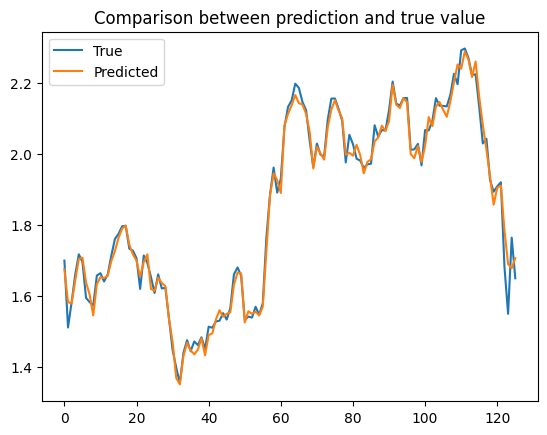

In [ ]:
plot_predictions(preds_SVM, y_test)

## SVM SciKit

Test MSE: 0.2449111102742845


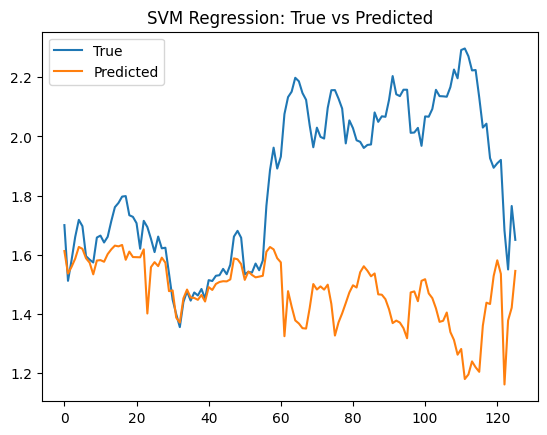

In [81]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Preprocessing (come nel tuo codice) ---
scaler = StandardScaler()
df_company, company_closings = get_dataframe(df, ["AAPL"])
df_company = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index)
company_closings = pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

X_train = df_company.iloc[:split_idx].to_numpy().astype(np.float32)
y_train = company_closings.iloc[:split_idx].to_numpy().ravel()  # vettore 1D
X_test = df_company.iloc[split_idx:].to_numpy().astype(np.float32)
y_test = company_closings.iloc[split_idx:].to_numpy().ravel()

# --- Definizione modello SVM ---
svm = SVR(kernel="rbf", C=1.0, epsilon=0.01)

# --- Training ---
svm.fit(X_train, y_train)

# --- Predizioni ---
preds = svm.predict(X_test)

# --- Valutazione ---
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, preds)
print("Test MSE:", mse)

# --- Plot ---
plt.plot(y_test, label="True")
plt.plot(preds, label="Predicted")
plt.legend()
plt.title("SVM Regression: True vs Predicted")
plt.show()


## **ANN**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ["APPL"])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

ValueError: Found array with 0 sample(s) (shape=(0, 5)) while a minimum of 1 is required by StandardScaler.

In [ ]:
X_train

array([[-1.3940899 , -1.3845874 , -1.4043342 ,  1.0569389 , -1.3703785 ],
       [-1.4009941 , -1.4039029 , -1.3840498 ,  1.3319478 , -1.3842849 ],
       [-1.4356424 , -1.4325018 , -1.4203525 ,  1.6616822 , -1.4029961 ],
       ...,
       [ 1.5446123 ,  1.5637349 ,  1.5373266 , -1.0021052 ,  1.5184145 ],
       [ 1.5942311 ,  1.596057  ,  1.5697894 , -0.96256906,  1.5846257 ],
       [ 1.689225  ,  1.6488193 ,  1.6202871 , -0.5300726 ,  1.5944129 ]],
      dtype=float32)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1129, 5)
(1129, 1)
(126, 5)
(126, 1)


In [ ]:
from torch.utils.data import Dataset

class MyANNDataset(Dataset):
    def __init__(self, X_data, y_data):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)

    def __len__(self):
      return len(self.y_data)

    def __getitem__(self, idx):
      x = self.X_data[idx]
      y = self.y_data[idx]

      return x, y

In [ ]:
from torch.utils.data import DataLoader

dataset = MyANNDataset(X_train, y_train)
loader_ANN = DataLoader(dataset, batch_size=32, shuffle=True)

In [ ]:
class ANN(nn.Module):
  def __init__(self, input_size):
    super(ANN, self).__init__()
    self.ann = nn.Sequential(
      nn.Linear(input_size, 64),
      nn.LeakyReLU(),
      nn.Linear(64, 1)
  )

  def forward(self, x):
    # input size x: (batch_size, n_features)
    return self.ann(x)

In [ ]:
# hyperparameters
input_size = 5
num_epochs = 100
lr = 0.001

model = ANN(input_size)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [ ]:
def train_ANN(model, epochs, loss_function, optimizer):
  dataset = MyANNDataset(X_train, y_train)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=True)

  n_total_steps = len(loader)

  model.to(device)
  model.train()

  for epoch in range(epochs):
    epoch_loss = 0
    for i, (samples, labels) in enumerate(loader_ANN):
      samples = samples.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)

      # Backward and optimize
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

In [ ]:
train_ANN(model, num_epochs, loss_function, optimizer)

Epoch [1/100], Step [36/35], Loss: 0.0203
Epoch [51/100], Step [36/35], Loss: 0.0002


In [ ]:
def test_ANN(model, loss_function):
  dataset = MyANNDataset(X_test, y_test)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=False)

  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader_ANN):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())

    actuals = y_test
    avg_loss = total_loss / len(loader_ANN.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_ANN, actuals_ANN = test_ANN(model, loss_function)

Test Loss: 0.0010


In [ ]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

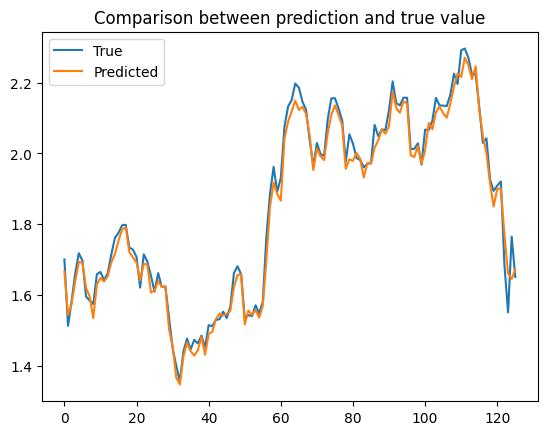

In [ ]:
plot_predictions(preds_ANN, y_test)

## **Comparison**

In [217]:
chosen_loss = mse_loss

In [216]:
# hyperparameters
input_size = 5
hidden_size = 48
num_epochs = 500
lr = [0.055, 0.04, 0.025, 0.01]
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

In [190]:
preds_LSTM_arr = []
actuals_LSTM_arr = []

In [191]:
for lr in lr:
  train_LSTM_scratch(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)
  preds_LSTM_tmp, actuals_LSTM_tmp = test_LSTM_scratch(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)
  preds_LSTM_arr.append(preds_LSTM_tmp)
  actuals_LSTM_arr.append(actuals_LSTM_tmp)

Epoch [50/500], Loss: 0.005415 [2025-08-24 18:14:54.129094]
Epoch [100/500], Loss: 0.004468 [2025-08-24 18:15:00.044074]
Epoch [150/500], Loss: 0.003981 [2025-08-24 18:15:05.326850]
Epoch [200/500], Loss: 0.003764 [2025-08-24 18:15:12.580065]
Epoch [250/500], Loss: 0.003465 [2025-08-24 18:15:17.880198]
Epoch [300/500], Loss: 0.003345 [2025-08-24 18:15:24.546039]
Epoch [350/500], Loss: 0.003266 [2025-08-24 18:15:29.965175]
Epoch [400/500], Loss: 0.003249 [2025-08-24 18:15:36.594243]
Epoch [450/500], Loss: 0.003209 [2025-08-24 18:15:42.015688]
Epoch [500/500], Loss: 0.003154 [2025-08-24 18:15:48.520216]
Test Loss: 0.0062
Epoch [50/500], Loss: 0.005564 [2025-08-24 18:15:55.673728]
Epoch [100/500], Loss: 0.004764 [2025-08-24 18:16:02.353485]
Epoch [150/500], Loss: 0.004526 [2025-08-24 18:16:07.631578]
Epoch [200/500], Loss: 0.004016 [2025-08-24 18:16:13.823130]
Epoch [250/500], Loss: 0.003753 [2025-08-24 18:16:19.899877]
Epoch [300/500], Loss: 0.003646 [2025-08-24 18:16:26.089355]
Epoch [3

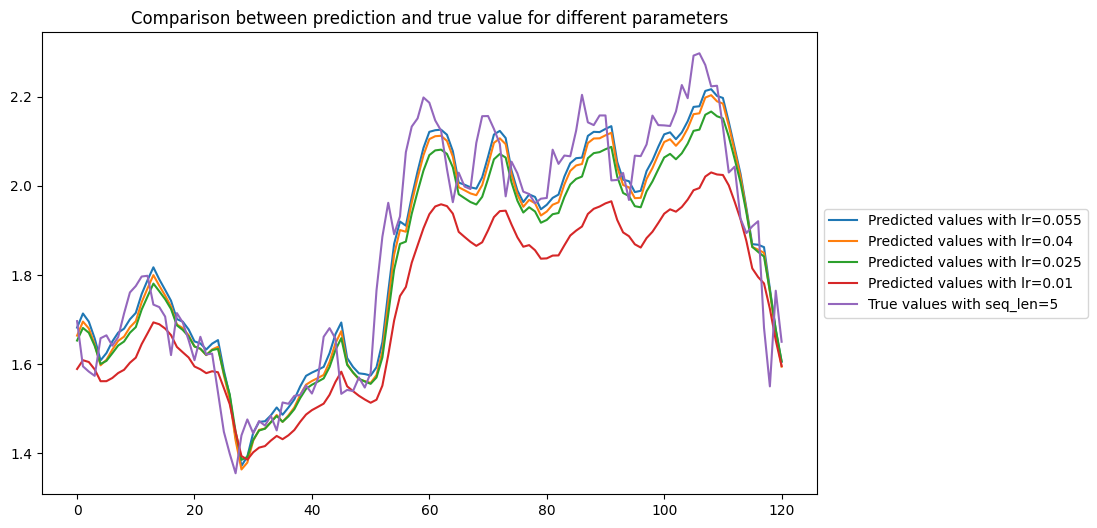

In [197]:
plt.figure(figsize=(10,6))
for i, lr_val in enumerate(lr):
  plt.plot(preds_LSTM_arr[i], label=f"Predicted values with lr={lr_val}")
plt.plot(actuals_LSTM_arr[0], label=f"True values with seq_len={seq_len}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title('Comparison between prediction and true value for different parameters')
plt.show()

In [218]:
preds_GAN_arr = []
actuals_GAN_arr = []

In [ ]:
for lr_G in lr:
  train_GAN(generator,discriminator,lr_D,lr_G,num_epochs,generator_loss,discriminator_loss,discriminator_optimizer,seq_len)
  preds_GAN, actuals_GAN = test_GAN(generator, seq_len, chosen_loss)
  preds_GAN_arr.append(preds_LSTM_tmp)
  actuals_GAN_arr.append(actuals_LSTM_tmp)

Epoch: 0 Loss D.: 1.5581456422805786
Epoch: 0 Loss G.: -0.21425780653953552
Epoch: 50 Loss D.: 1.403800368309021
Epoch: 50 Loss G.: -0.20584097504615784
Epoch: 100 Loss D.: 1.3974430561065674
Epoch: 100 Loss G.: -0.2041628211736679
Epoch: 150 Loss D.: 1.4318287372589111
Epoch: 150 Loss G.: -0.25507768988609314
Epoch: 200 Loss D.: 1.3497326374053955
Epoch: 200 Loss G.: -0.24333953857421875
Epoch: 250 Loss D.: 1.4276537895202637
Epoch: 250 Loss G.: -0.20877814292907715
Epoch: 300 Loss D.: 1.3971598148345947
Epoch: 300 Loss G.: -0.2173493206501007
Epoch: 350 Loss D.: 1.3878095149993896
Epoch: 350 Loss G.: -0.2066110223531723
Epoch: 400 Loss D.: 1.343168020248413
Epoch: 400 Loss G.: -0.2408865988254547
Epoch: 450 Loss D.: 1.3484894037246704
Epoch: 450 Loss G.: -0.19279369711875916
Test Loss: 0.0013
Epoch: 0 Loss D.: 1.3134647607803345
Epoch: 0 Loss G.: -0.21810674667358398
Epoch: 50 Loss D.: 1.4181687831878662
Epoch: 50 Loss G.: -0.20407453179359436
Epoch: 100 Loss D.: 1.372388243675232
Ep

In [ ]:
plt.figure(figsize=(10,6))
for i, lr_val in enumerate(lr):
  plt.plot(preds_GAN_arr[i], label=f"Predicted values with lr={lr_val}")
plt.plot(actuals_GAN_arr[0], label=f"True values with seq_len={seq_len}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title('Comparison between prediction and true value for different parameters')
plt.show()

In [101]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

### **Loss functions for comparison (da provare per vedere se funziona)**

These are **loss functions** we use to understand how much our predictions deviate from the true data, and we specifically use these for consistency with the paper we are referencing.


1.   **Mean Absolute Error (MAE)**

  \begin{align}
  \text{MAE} = \frac{1}{N}\sum_{k=1}^{N} \lvert \hat{y}_k - y_k \rvert
  \end{align}

   - Measures the average absolute deviation between predictions and true values.
   - Useful when you want the “typical” prediction error.

2.   **Root Mean Squared Error (RMAE / RMSE)**

  \begin{align}
  \text{RMAE} = \sqrt{ \frac{1}{N} \sum_{{k=1}^{N}} (\hat{y}_k - y_k)^2 }
  \end{align}

  - Penalizes larger errors more heavily
  - Useful when large deviations are more critical than small ones.
  - Sensitive to outliers

3. **Relative MAE**

  \begin{align}
  \text{Relative MAE} = \frac{1}{N} \sum_{k=1}^{N} \frac{\lvert \hat{y}_k - y_k \rvert}{y_k}
  \end{align}

  - Measures error relative to the true value.
  - Useful when the data spans very different scales.

4. **Average Rise (AR)**

  \begin{align}
  \text{AR} = \frac{1}{N-1} \sum_{k=1}^{N-1} (y_{k+1} - y_k) \quad \text{if } \hat{y}_{k+1} > \hat{y}_k
  \end{align}

  - Captures the model’s ability to follow trends rather than exact values.  
  - Useful for time series or ordered data, focusing on correct increases.

In [102]:
def mae(y_true, y_pred):
    """
    Mean Absolute Error
    """
    return jnp.mean(jnp.abs(y_pred - y_true))

def rmae(y_true, y_pred):
    """
    Root Mean Squared Error
    """
    return jnp.sqrt(jnp.mean((y_pred - y_true)**2))

def relative_mae(y_true, y_pred):
    """
    Relative MAE
    """
    safe_y_true = jnp.where(y_true != 0, y_true, 1.0)
    return jnp.mean(jnp.abs(y_pred - y_true) / safe_y_true)

def ar(y_true, y_pred):
    """
    AR = 1/(N-1) * sum((y_{k+1} - y_k) if y_pred_{k+1} > y_pred_k)
    """
    diffs = y_true[1:] - y_true[:-1]
    mask = y_pred[1:] > y_pred[:-1]
    masked_diffs = diffs * mask
    count = jnp.sum(mask)
    return jnp.where(count > 0, jnp.sum(masked_diffs) / count, 0.0)

In [103]:
loss_functions = {
    "MAE": mae,
    "RMAE": rmae,
    "Relative MAE": relative_mae,
    "AR": ar
}

In [122]:
predictions_results = {'GAN': preds_GAN, 'LSTM': preds_LSTM_scratch}

Here we create a function to evaluate the quality of the selected models based on various metrics.

In [123]:
def evaluate_losses(predictions_results, loss_funcs, y_true):
    """
    Evaluate multiple loss functions on multiple prediction arrays.

    Args:
        predictions_results (dict): keys = model names, values = arrays of predictions
        loss_funcs (dict): keys = loss names, values = functions(loss(y_true, y_pred))
        y_true (array-like): true values

    Returns:
        dict: nested dictionary {model_name: {loss_name: loss_value}}
    """
    y_true = jnp.array(y_true)
    results = {}

    for model_name, preds in predictions_results.items():
        preds = jnp.array(preds)
        results[model_name] = {}
        for loss_name, loss_fn in loss_funcs.items():
            results[model_name][loss_name] = float(loss_fn(y_true, preds))

    return results

In [146]:
losses_results = evaluate_losses(predictions_results, loss_functions, y_test[:-seq_len])

Here we display the results of the metrics, highlighting the best values.

In [147]:
def results_to_table(results):
    """
    Convert nested dictionary of results into a styled pandas DataFrame
    highlighting the minimum values for each loss.

    Args:
        results (dict): nested dictionary {model_name: {loss_name: value}}

    Returns:
        pd.DataFrame.style: styled DataFrame
    """
    df = pd.DataFrame(results).T

    styled_df = df.style.highlight_min(axis=0, color='lightgreen').format("{:.4f}")
    return styled_df

In [148]:
results_to_table(losses_results)

,MAE,RMAE,Relative MAE,AR
GAN,0.0900,0.1130,0.0497,0.0036
LSTM,0.1567,0.1875,0.0824,0.0024


### **Visual comparison between models**

In [149]:
def plot_predictions_comparison(models_predictions, actuals):
  plt.plot(actuals, label='True')

  for (model, preds) in models_predictions.items():
    plt.plot(preds, label=model)

  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

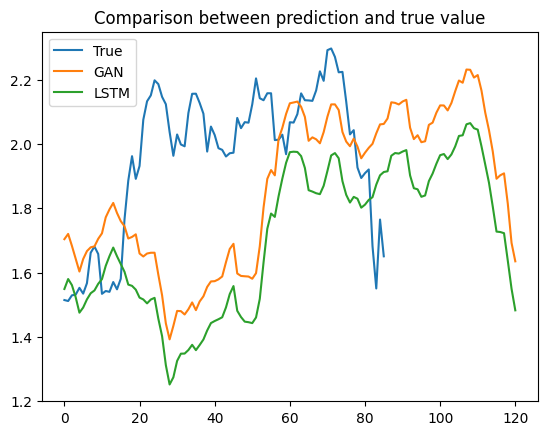

In [150]:
plot_predictions_comparison(predictions_results, y_test[40:])